In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier

dataset = pd.read_csv('/content/drive/MyDrive/Datasets/titanic.csv')
print("Size of dataset:", dataset.shape)

dataset.head()

print("Checking for missing values:\n")
print(dataset.isnull().sum())

dataset["Age"] = dataset["Age"].fillna(dataset["Age"].mean())
dataset["Embarked"] = dataset["Embarked"].fillna(dataset["Embarked"].mode()[0])
dataset["Cabin"] = dataset["Cabin"].fillna(dataset["Cabin"].mode()[0])

dataset["Pclass"] = dataset["Pclass"].apply(str)

for col in dataset.dtypes[dataset.dtypes == "object"].index:
    for_dummy = dataset.pop(col)
    dataset = pd.concat([dataset, pd.get_dummies(for_dummy, prefix=col)], axis=1)

dataset.head()

labels = dataset.pop("Survived")

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(dataset, labels, test_size=0.25)

rf = RandomForestClassifier(n_estimators=30, n_jobs=1)
rf.fit(X_train, y_train)

print("No. of decision trees created:", len(rf.estimators_))

y_pred = rf.predict(X_test)

Size of dataset: (891, 12)
Checking for missing values:

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
No. of decision trees created: 30


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score, auc

false_positive_rate, true_positive_rate, thresholds = roc_curve(y_test, y_pred)
roc_auc = auc(false_positive_rate, true_positive_rate)

print("ROC AUC:", roc_auc)

ROC AUC: 0.7884060431166185


In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, auc

n_estimators = [1, 2, 4, 8, 16, 32, 64, 100, 200]
train_results = []
test_results = []

for estimator in n_estimators:
    rf = RandomForestClassifier(n_estimators=estimator, n_jobs=1)
    rf.fit(X_train, y_train)

    # Train AUC
    train_pred = rf.predict(X_train)
    fpr, tpr, _ = roc_curve(y_train, train_pred)
    roc_auc = auc(fpr, tpr)
    train_results.append(roc_auc)

    # Test AUC
    y_pred = rf.predict(X_test)
    fpr, tpr, _ = roc_curve(y_test, y_pred)
    roc_auc = auc(fpr, tpr)
    test_results.append(roc_auc)

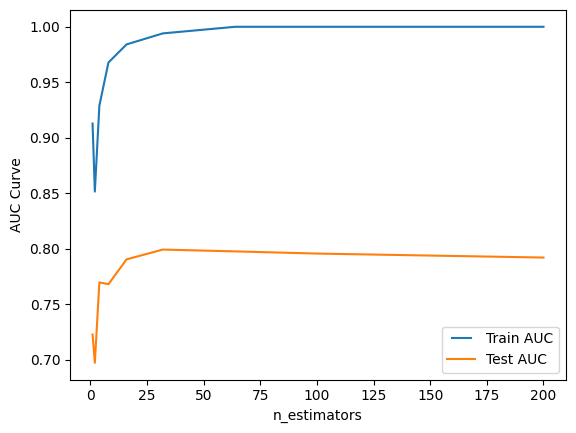

In [ ]:
from matplotlib.legend_handler import HandlerLine2D

line1, = plt.plot(n_estimators, train_results, label="Train AUC")
line2, = plt.plot(n_estimators, test_results, label="Test AUC")

plt.legend(handler_map={line1: HandlerLine2D(numpoints=2)})
plt.ylabel("AUC Curve")
plt.xlabel("n_estimators")
plt.show()

In [ ]:
rf = RandomForestClassifier(n_estimators=30)
rf.fit(X_train, y_train)

print("No. of decision trees created:", len(rf.estimators_))

No. of decision trees created: 30


In [ ]:
y_pred = rf.predict(X_test)

false_positive_rate, true_positive_rate, thresholds = roc_curve(y_test, y_pred)
roc_auc = auc(false_positive_rate, true_positive_rate)

print("ROC AUC:", roc_auc)

ROC AUC: 0.801294903926483


[Text(0.9290400552486188, 0.995, 'x[590] <= 0.5\ngini = 0.459\nsamples = 430\nvalue = [430.0, 238.0]'),
 Text(0.9216735727440147, 0.985, 'x[266] <= 0.5\ngini = 0.456\nsamples = 429\nvalue = [430.0, 234.0]'),
 Text(0.9253568139963168, 0.99, 'True  '),
 Text(0.9143070902394107, 0.975, 'x[823] <= 0.5\ngini = 0.455\nsamples = 428\nvalue = [430.0, 232.0]'),
 Text(0.9069406077348067, 0.965, 'x[2] <= 2.5\ngini = 0.453\nsamples = 427\nvalue = [430.0, 229.0]'),
 Text(0.8359806629834254, 0.955, 'x[449] <= 0.5\ngini = 0.462\nsamples = 404\nvalue = [397.0, 225.0]'),
 Text(0.8286141804788214, 0.945, 'x[5] <= 0.5\ngini = 0.46\nsamples = 403\nvalue = [397, 222]'),
 Text(0.708793738489871, 0.935, 'x[1144] <= 0.5\ngini = 0.385\nsamples = 298\nvalue = [335, 118]'),
 Text(0.701427255985267, 0.925, 'x[295] <= 0.5\ngini = 0.384\nsamples = 297\nvalue = [335, 117]'),
 Text(0.694060773480663, 0.915, 'x[581] <= 0.5\ngini = 0.377\nsamples = 296\nvalue = [335, 113]'),
 Text(0.6866942909760589, 0.905, 'x[1462] <=

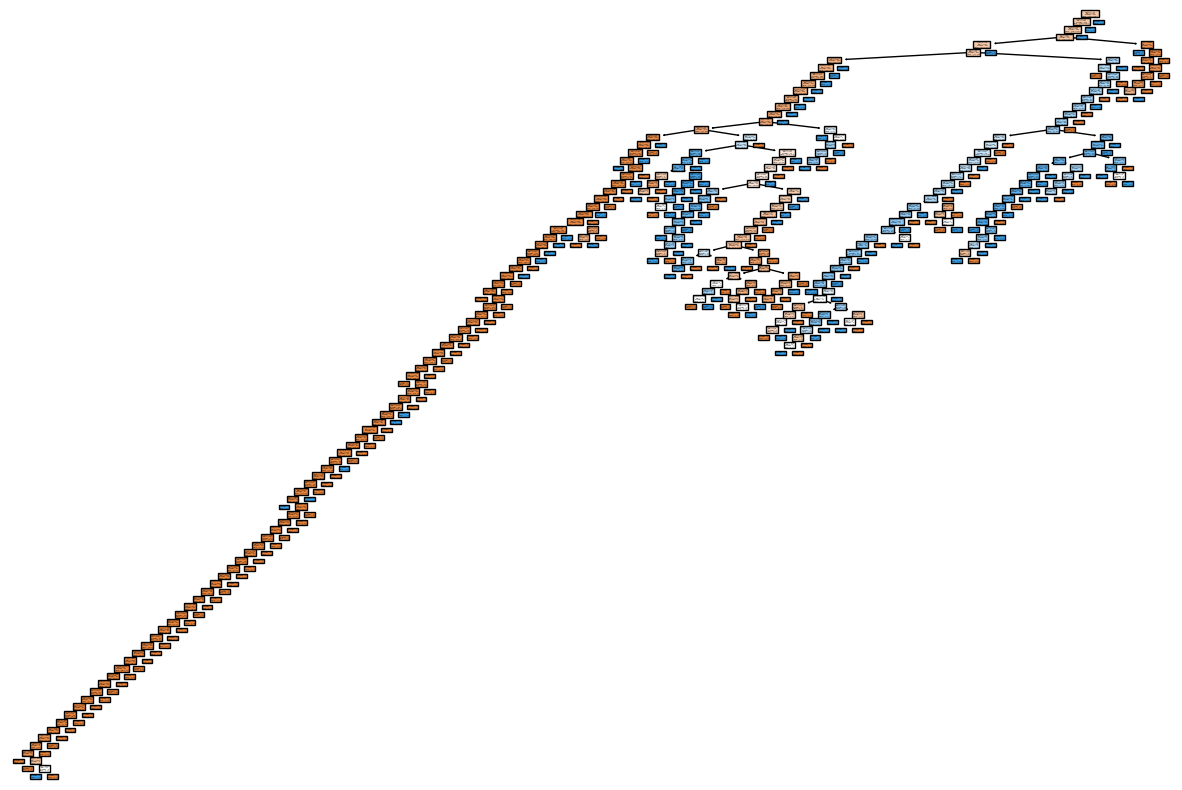

In [ ]:
plt.figure(figsize=(15, 10))
tree.plot_tree(rf.estimators_[4], filled=True)